In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import load, dump


### Datasets

In [69]:
corrs = load('correlations.joblib')

In [2]:

with pd.HDFStore('elasticnet_results.h5') as store:
    print(store.keys())

['/A2M', '/AAAS', '/AACS', '/AAGAB', '/AAK1', '/AAMDC', '/AAMP', '/AAR2', '/AARS', '/AARS2', '/AARSD1', '/AASDHPPT', '/AASS', '/AATF', '/ABCB10', '/ABCB6', '/ABCB7', '/ABCB8', '/ABCC1', '/ABCC4', '/ABCD1', '/ABCD3', '/ABCE1', '/ABCF1', '/ABCF2', '/ABCF3', '/ABHD10', '/ABHD11', '/ABHD12', '/ABHD14B', '/ABHD16A', '/ABI1', '/ABI2', '/ABLIM1', '/ABT1', '/ACAA1', '/ACAA2', '/ACACA', '/ACAD10', '/ACAD8', '/ACAD9', '/ACADM', '/ACADS', '/ACADSB', '/ACADVL', '/ACAP2', '/ACAT1', '/ACAT2', '/ACBD3', '/ACBD5', '/ACBD6', '/ACIN1', '/ACLY', '/ACO1', '/ACO2', '/ACOT13', '/ACOT2', '/ACOT7', '/ACOT8', '/ACOT9', '/ACOX1', '/ACP1', '/ACP2', '/ACP6', '/ACSF2', '/ACSF3', '/ACSL1', '/ACSL3', '/ACSL4', '/ACSL5', '/ACSS2', '/ACTA2', '/ACTB', '/ACTL6A', '/ACTL8', '/ACTN1', '/ACTN4', '/ACTR10', '/ACTR1A', '/ACTR2', '/ACTR3', '/ACTR5', '/ACY1', '/ACYP1', '/ACYP2', '/ADA', '/ADAM10', '/ADAM15', '/ADAM17', '/ADAM9', '/ADAR', '/ADCK3', '/ADCK4', '/ADD1', '/ADD3', '/ADH5', '/ADI1', '/ADIRF', '/ADK', '/ADNP', '/ADO',

In [7]:
A2M = pd.read_hdf('elasticnet_results.h5', key='/A2M')  # replace '/df1' with actual key


In [8]:
A2M

,protein,LOO sample,true,predicted,params_dict
0,A2M,MDAMB468_BREAST,-0.345562,-0.276651,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
1,A2M,SH4_SKIN,1.642186,0.308402,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
2,A2M,AU565_BREAST,-1.129114,-0.899868,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
3,A2M,KMRC1_KIDNEY,1.493333,-0.222243,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
4,A2M,CAL51_BREAST,0.274652,0.275565,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
...,...,...,...,...,...
364,A2M,FADU_UPPER_AERODIGESTIVE_TRACT,-1.116991,-0.698824,"{""alpha"": 0.1, ""l1_ratio"": 0.9}"
365,A2M,KP4_PANCREAS,1.922976,-0.334505,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
366,A2M,MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,-1.106344,-0.849375,"{""alpha"": 0.1, ""l1_ratio"": 0.9}"
367,A2M,OVCAR8_OVARY,-0.770372,0.063654,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"


In [5]:
# Load all data from the HDF5 file
h5_file = 'elasticnet_results.h5'
eps = 1e-8

with pd.HDFStore(h5_file) as store:
    keys = store.keys()
    df_list = [store[key] for key in keys]
    combined_df = pd.concat(df_list, ignore_index=True)

# Compute absolute and squared errors
combined_df['abs_error'] = (combined_df['true'] - combined_df['predicted']).abs()
combined_df['squared_error'] = (combined_df['true'] - combined_df['predicted'])**2
combined_df['rel_error']     = combined_df['abs_error'] / (combined_df['true'].abs() + eps)

combined_df.head()


,protein,LOO sample,true,predicted,params_dict,abs_error,squared_error,rel_error
0,A2M,MDAMB468_BREAST,-0.345562,-0.276651,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",0.068912,4.748821e-03,0.199419
1,A2M,SH4_SKIN,1.642186,0.308402,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",1.333784,1.778980e+00,0.812200
2,A2M,AU565_BREAST,-1.129114,-0.899868,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",0.229246,5.255372e-02,0.203032
3,A2M,KMRC1_KIDNEY,1.493333,-0.222243,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",1.715576,2.943201e+00,1.148823
4,A2M,CAL51_BREAST,0.274652,0.275565,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",0.000913,8.334106e-07,0.003324


##  Protein-wise analysis


### Statistics on errors 

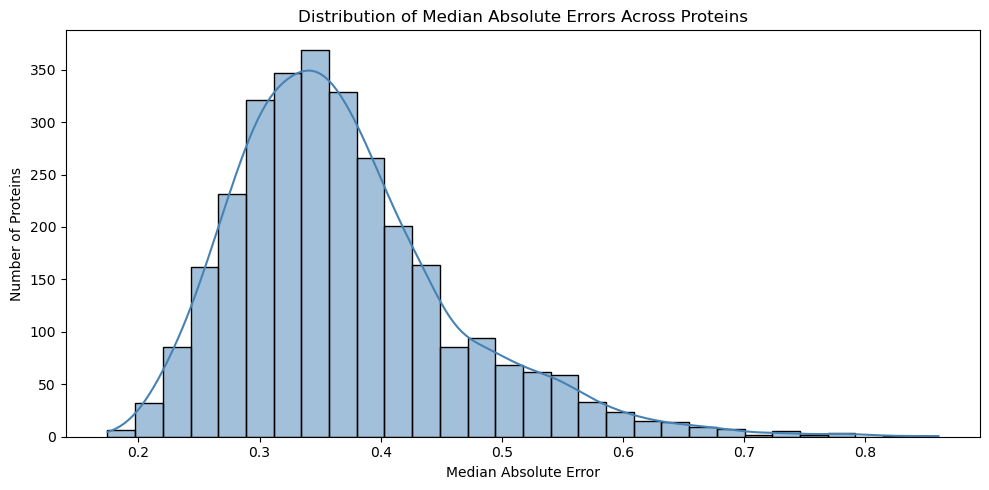

In [ ]:

# 1. Compute median absolute error for each protein across samples
protein_medians = combined_df.groupby("protein")["abs_error"].median().reset_index()
protein_medians.rename(columns={"abs_error": "median_abs_error"}, inplace=True)

# 2. Plot the distribution
plt.figure(figsize=(10, 5))
sns.histplot(protein_medians["median_abs_error"], bins=30, kde=True, color="steelblue")

plt.title("Distribution of Median Absolute Errors Across Proteins")
plt.xlabel("Median Absolute Error")
plt.ylabel("Number of Proteins")
plt.tight_layout()
plt.show()

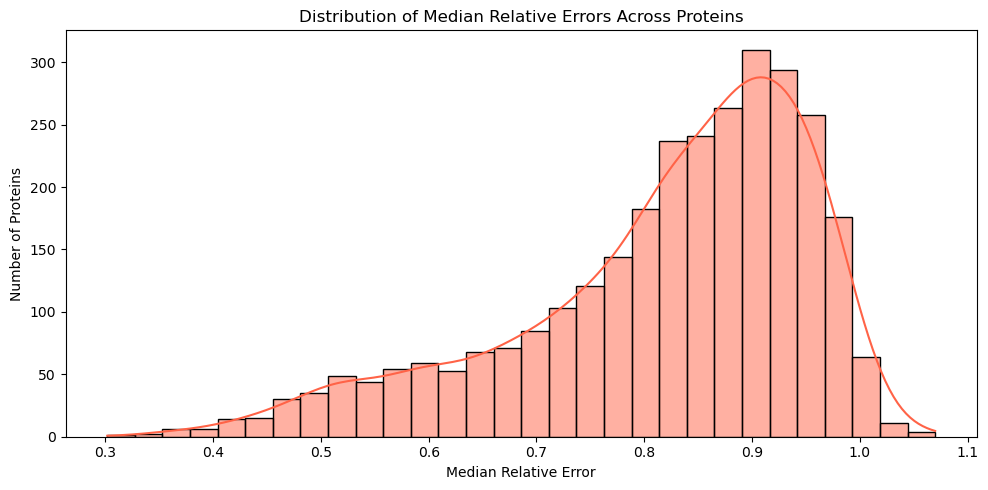

In [ ]:
# Compute median relative error across all samples per protein
protein_medians_rel = combined_df.groupby("protein")["rel_error"].median().reset_index()
protein_medians_rel.rename(columns={"rel_error": "median_rel_error"}, inplace=True)

# Plot
plt.figure(figsize=(10, 5))
sns.histplot(protein_medians_rel["median_rel_error"], bins=30, kde=True, color="tomato")

plt.title("Distribution of Median Relative Errors Across Proteins")
plt.xlabel("Median Relative Error")
plt.ylabel("Number of Proteins")
plt.tight_layout()
plt.show()


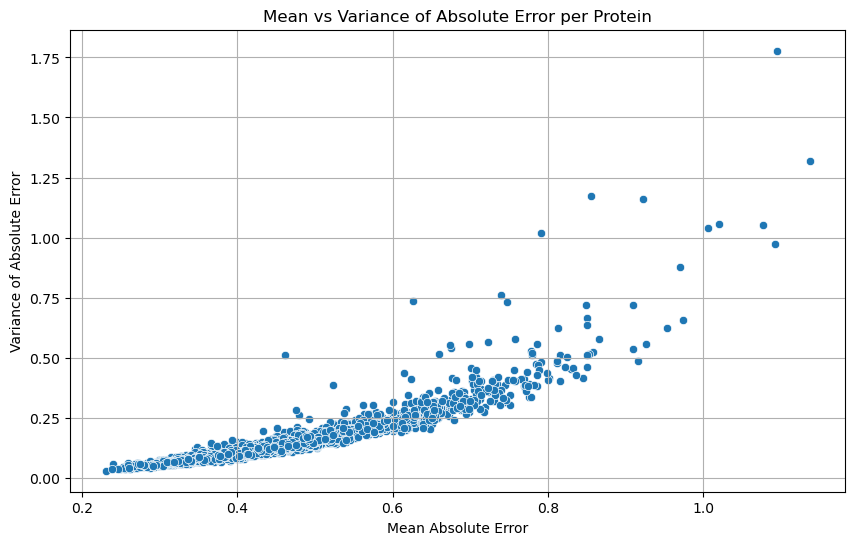

In [ ]:
# Mean and variance per protein
protein_stats = combined_df.groupby('protein')['abs_error'].agg(['mean', 'var']).reset_index()

# Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=protein_stats, x='mean', y='var')
plt.title("Mean vs Variance of Absolute Error per Protein")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Variance of Absolute Error")
plt.grid(True)
plt.show()


#### mean error vs variance of true values

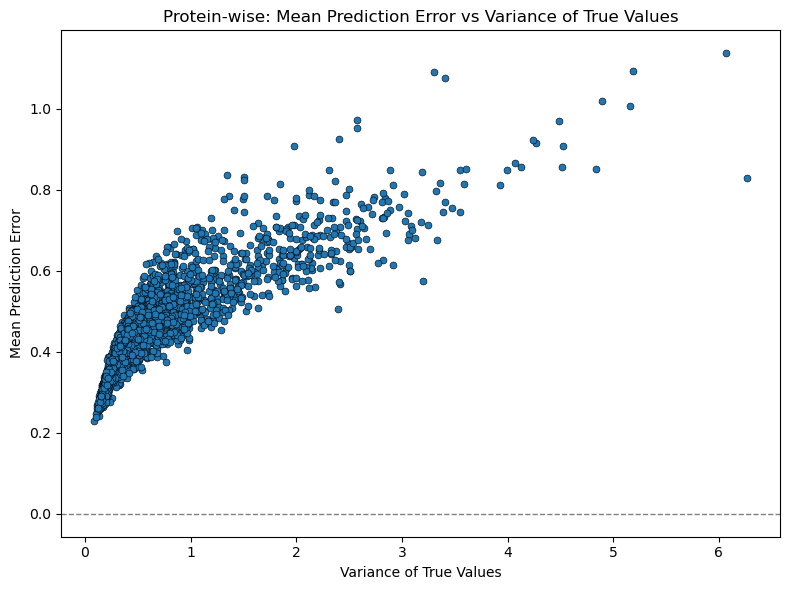

In [ ]:
#Aggregate per protein 

prot_stats = (
    combined_df
    .groupby('protein')
    .agg(
        mean_error = ('abs_error', 'mean'),
        var_true   = ('true', 'var'),
    )
    .reset_index()
)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=prot_stats,
    x='var_true',
    y='mean_error',
    s=25,
    edgecolor='k'
)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Protein‑wise: Mean Prediction Error vs Variance of True Values')
plt.xlabel('Variance of True Values')
plt.ylabel('Mean Prediction Error')
plt.tight_layout()
plt.show()

### Best proteins and Samples analysis


In [56]:
protein_error_summary = combined_df.groupby('protein').agg(
    median_abs_error=('abs_error', 'median'),
    std_abs_error=('abs_error', 'std'),
    median_squared_error=('squared_error', 'median'),
    std_squared_error=('squared_error', 'std'),
    #count=('protein', 'count')
    median_rel_error=('rel_error', 'median'),
    std_rel_error=('rel_error', 'std')
).sort_values(by='median_abs_error', ascending=True)

protein_error_summary.head(10)


,median_abs_error,std_abs_error,median_squared_error,std_squared_error,median_rel_error,std_rel_error
protein,,,,,,
DYNLL1,0.174422,0.239938,0.030423,0.319245,0.969939,14.855984
EFTUD2,0.191662,0.216726,0.036734,0.205133,0.913878,7.038567
DDX1,0.193204,0.173331,0.037328,0.121448,0.985085,7.893417
NUP93,0.194600,0.231569,0.037869,0.267437,0.979429,6.988987
MIB1,0.195952,0.187762,0.038397,0.144643,0.933940,47.467600
CSNK2B,0.196920,0.241188,0.038777,0.270643,0.998662,8.337999
CNOT10,0.198723,0.251019,0.039491,0.340711,0.959223,13.640753
GABPA,0.202890,0.224131,0.041164,0.186973,0.897679,15.484019
KPNA4,0.203597,0.238654,0.041452,0.281514,0.889050,3.455073


In [43]:
protein_name = 'DYNLL1'
# Filter combined_df for that protein
protein_df = combined_df[combined_df['protein'] == protein_name]
# Sort SAMPLES by absolute error
protein_df_sorted = protein_df.sort_values(by='abs_error', ascending=True)
# Display
smallest_error = protein_df_sorted[protein_df_sorted["abs_error"]< 0.1]
smallest_error[['LOO sample', 'abs_error']]  

,LOO sample,abs_error
465082,HCC2218_BREAST,0.000168
465029,A549_LUNG,0.001852
464987,BT549_BREAST,0.001941
465174,KYM1_SOFT_TISSUE,0.003911
465273,UMUC3_URINARY_TRACT,0.003959
...,...,...
465150,HEC6_ENDOMETRIUM,0.093950
464953,KMRC20_KIDNEY,0.094580
465066,LOXIMVI_SKIN,0.096903
465023,LK2_LUNG,0.097010


display the samples with less than 0.1 error

In [38]:
def get_less_than01(protein_name, df, error_col='abs_error', sample_col='LOO sample'):
    protein_df = df[df['protein'] == protein_name]
    sorted_df = protein_df.sort_values(by=error_col, ascending=True)
    return sorted_df[[sample_col, error_col]].query(f"{error_col} < 0.1")

small = get_less_than01('DYNLL1', combined_df)
small


,LOO sample,abs_error
465082,HCC2218_BREAST,0.000168
465029,A549_LUNG,0.001852
464987,BT549_BREAST,0.001941
465174,KYM1_SOFT_TISSUE,0.003911
465273,UMUC3_URINARY_TRACT,0.003959
...,...,...
465150,HEC6_ENDOMETRIUM,0.093950
464953,KMRC20_KIDNEY,0.094580
465066,LOXIMVI_SKIN,0.096903
465023,LK2_LUNG,0.097010


Check between the best proteins for absolute error if the samples correspond

In [44]:
# Get the top 10 proteins with the lowest median absolute error
top_10_proteins = protein_error_summary.head(10).index.tolist()

# Dictionary to store results
low_error_samples_by_protein = {}

# Loop through top 10 proteins and apply your function
for prot in top_10_proteins:
    low_error_samples_by_protein[prot] = get_less_than01(prot, combined_df)

# see low-error samples for the first protein
low_error_samples_by_protein[top_10_proteins[0]]
summary = {
    prot: len(df)
    for prot, df in low_error_samples_by_protein.items()
}

summary_df = pd.DataFrame.from_dict(summary, orient='index', columns=['low_error_count'])
summary_df


,low_error_count
DYNLL1,115
EFTUD2,100
DDX1,91
NUP93,98
MIB1,94
CSNK2B,91
CNOT10,97
GABPA,99
KPNA4,84
ACTA2,93


In [46]:
low_error_sample_sets = {
    prot: set(get_less_than01(prot, combined_df)['LOO sample'])
    for prot in top_10_proteins
}

# Find intersection: samples that are low-error across *all* top 10 proteins
common_low_error_samples = set.union(*low_error_sample_sets.values())

print(f"Number of samples with abs_error < 0.1 across ALL top 10 proteins: {len(common_low_error_samples)}")
print("Common samples:", common_low_error_samples)

Number of samples with abs_error < 0.1 across ALL top 10 proteins: 346
Common samples: {'LN229_CENTRAL_NERVOUS_SYSTEM', 'MFE319_ENDOMETRIUM', 'HUPT4_PANCREAS', 'SNU1079_BILIARY_TRACT', 'A704_KIDNEY', 'CL34_LARGE_INTESTINE', '22RV1_PROSTATE', 'EFM19_BREAST', 'HS294T_SKIN', 'HT55_LARGE_INTESTINE', 'SNGM_ENDOMETRIUM', 'RD_SOFT_TISSUE', 'T47D_BREAST', 'MOLM13_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'OVCAR4_OVARY', 'QGP1_PANCREAS', 'KMS11_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'SBC5_LUNG', 'G401_SOFT_TISSUE', 'SKHEP1_LIVER', 'OV90_OVARY', 'TC71_BONE', 'PANC0203_PANCREAS', 'HS695T_SKIN', 'TE11_OESOPHAGUS', 'MFE296_ENDOMETRIUM', 'REC1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'SW837_LARGE_INTESTINE', 'NCIH1693_LUNG', 'HEC50B_ENDOMETRIUM', 'HCC38_BREAST', 'HCC2218_BREAST', 'SNU1_STOMACH', 'SNU719_STOMACH', 'HUPT3_PANCREAS', 'CAL33_UPPER_AERODIGESTIVE_TRACT', 'NCIH647_LUNG', 'CORL47_LUNG', 'KMS27_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'JM1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'COLO678_LARGE_INTESTINE', 'LN

hoe many times a tissue appears in the top predicted proteins

In [54]:
# Convert the union of sets to a list before using it as index
all_samples = list(set.union(*low_error_sample_sets.values()))

# Create the sample matrix with proper indexing
sample_matrix = pd.DataFrame(index=all_samples)

# Populate the matrix with binary indicators
for prot, sample_set in low_error_sample_sets.items():
    sample_matrix[prot] = sample_matrix.index.isin(sample_set).astype(int)

# Count in how many proteins each sample appears
sample_matrix['num_proteins'] = sample_matrix.sum(axis=1)

# Sort to find the most consistent low-error samples
sample_matrix_sorted = sample_matrix.sort_values(by='num_proteins', ascending=False)

# Step 1: Reset index to get sample names as a column
sample_matrix_reset = sample_matrix_sorted.reset_index().rename(columns={'index': 'sample'})

# Step 2: Extract tissue type from sample names (split by last underscore)
sample_matrix_reset['tissue'] = sample_matrix_reset['sample'].apply(lambda x: x.split('_')[-1])

# Step 3: Group by tissue and sum across all protein columns
tissue_summary = sample_matrix_reset.groupby('tissue').sum(numeric_only=True)

# Optional: Sort by number of appearances across proteins
tissue_summary = tissue_summary.sort_values(by='num_proteins', ascending=False)

tissue_summary.head(10)


,DYNLL1,EFTUD2,DDX1,NUP93,MIB1,CSNK2B,CNOT10,GABPA,KPNA4,ACTA2,num_proteins
tissue,,,,,,,,,,,
LUNG,20,16,18,19,18,24,30,19,21,15,200
SKIN,16,10,7,11,9,5,11,9,7,9,94
TISSUE,4,9,10,14,8,10,9,12,6,11,93
INTESTINE,11,12,9,8,8,5,6,10,9,8,86
BREAST,8,5,7,8,11,8,9,7,7,11,81
PANCREAS,3,6,6,3,5,3,5,5,5,6,47
TRACT,7,9,2,10,2,6,4,1,3,2,46
LIVER,9,2,5,3,6,5,1,5,4,6,46
OVARY,5,6,6,2,4,4,2,6,4,5,44


### MAE vs correlations

In [70]:
corrs

,pearson,spearman,kendall
A2M,0.373828,0.230195,0.157938
AAAS,0.033262,0.054040,0.037045
AACS,0.475468,0.446383,0.309187
AAGAB,0.345481,0.402540,0.279094
AAK1,0.623951,0.585448,0.414043
...,...,...,...
ZWINT,0.287495,0.285369,0.193985
ZYG11B,0.327869,0.335152,0.227918
ZYX,0.685739,0.657462,0.478076
ZZEF1,0.343196,0.383925,0.260961


In [68]:
sorted(protein_error_summary.index)

['A2M',
 'AAAS',
 'AACS',
 'AAGAB',
 'AAK1',
 'AAMDC',
 'AAMP',
 'AAR2',
 'AARS',
 'AARS2',
 'AARSD1',
 'AASDHPPT',
 'AASS',
 'AATF',
 'ABCB10',
 'ABCB6',
 'ABCB7',
 'ABCB8',
 'ABCC1',
 'ABCC4',
 'ABCD1',
 'ABCD3',
 'ABCE1',
 'ABCF1',
 'ABCF2',
 'ABCF3',
 'ABHD10',
 'ABHD11',
 'ABHD12',
 'ABHD14B',
 'ABHD16A',
 'ABI1',
 'ABI2',
 'ABLIM1',
 'ABT1',
 'ACAA1',
 'ACAA2',
 'ACACA',
 'ACAD10',
 'ACAD8',
 'ACAD9',
 'ACADM',
 'ACADS',
 'ACADSB',
 'ACADVL',
 'ACAP2',
 'ACAT1',
 'ACAT2',
 'ACBD3',
 'ACBD5',
 'ACBD6',
 'ACIN1',
 'ACLY',
 'ACO1',
 'ACO2',
 'ACOT13',
 'ACOT2',
 'ACOT7',
 'ACOT8',
 'ACOT9',
 'ACOX1',
 'ACP1',
 'ACP2',
 'ACP6',
 'ACSF2',
 'ACSF3',
 'ACSL1',
 'ACSL3',
 'ACSL4',
 'ACSL5',
 'ACSS2',
 'ACTA2',
 'ACTB',
 'ACTL6A',
 'ACTL8',
 'ACTN1',
 'ACTN4',
 'ACTR10',
 'ACTR1A',
 'ACTR2',
 'ACTR3',
 'ACTR5',
 'ACY1',
 'ACYP1',
 'ACYP2',
 'ADA',
 'ADAM10',
 'ADAM15',
 'ADAM17',
 'ADAM9',
 'ADAR',
 'ADCK3',
 'ADCK4',
 'ADD1',
 'ADD3',
 'ADH5',
 'ADI1',
 'ADIRF',
 'ADK',
 'ADNP',
 'ADO',


In [77]:
corrs.reindex(protein_error_summary.index)

,pearson,spearman,kendall
protein,,,
DYNLL1,0.380480,0.321732,0.221931
EFTUD2,0.070542,0.075721,0.051963
DDX1,0.232642,0.202941,0.135755
NUP93,0.063619,0.075277,0.052673
MIB1,0.313332,0.266452,0.180101
...,...,...,...
MT1G,0.149165,0.007811,0.007243
CRIP1,0.784473,0.753635,0.549170
CDKN2A,0.551237,0.575559,0.399110


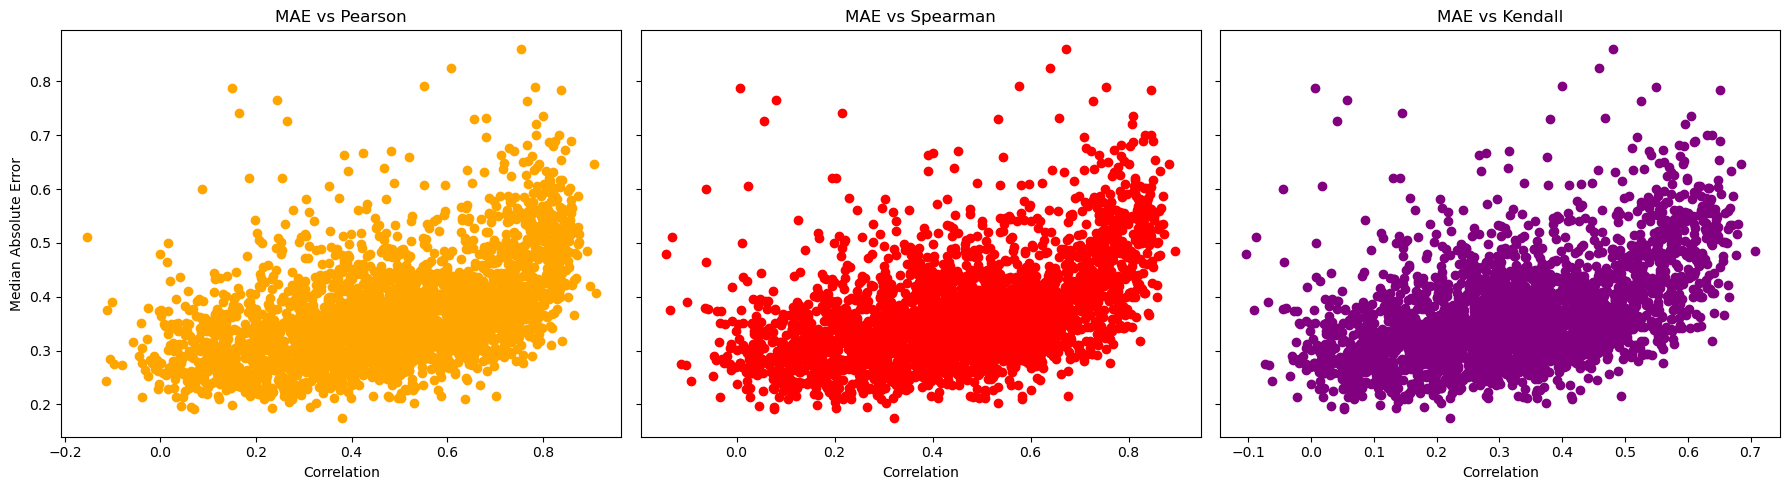

In [83]:

mae = protein_error_summary['median_abs_error']

# Define custom colors for each correlation type
colors = ['orange', 'red', 'purple']  # Feel free to change these

# Create subplots: 1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# Plot each correlation type separately
for ax, col, color in zip(axes, corrs.columns, colors):
    ax.scatter(corrs[col], mae, color=color)
    ax.set_title(f'MAE vs {col.capitalize()}')
    ax.set_xlabel('Correlation')
    ax.grid(False)

# Common Y label
axes[0].set_ylabel('Median Absolute Error')

plt.tight_layout()
plt.show()



## Samples

In [ ]:
sample_error_summary = combined_df.groupby('LOO sample').agg(
    mean_abs_error=('abs_error', 'mean'),
    std_abs_error=('abs_error', 'std'),
    mean_squared_error=('squared_error', 'mean'),
    std_squared_error=('squared_error', 'std'),
    count=('LOO sample', 'count')
).sort_values(by='mean_abs_error', ascending=False)

sample_error_summary.head()

,mean_abs_error,std_abs_error,mean_squared_error,std_squared_error,count
LOO sample,,,,,
RCHACV_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.920915,0.617301,1.229018,1.506187,3000
MOLM13_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.770507,0.581904,0.932180,1.410704,3000
KNS81_CENTRAL_NERVOUS_SYSTEM,0.728998,0.538527,0.821353,1.154276,3000
MONOMAC1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.712235,0.504966,0.762184,0.975983,3000
IM95_STOMACH,0.708313,0.542428,0.795837,1.659184,3000


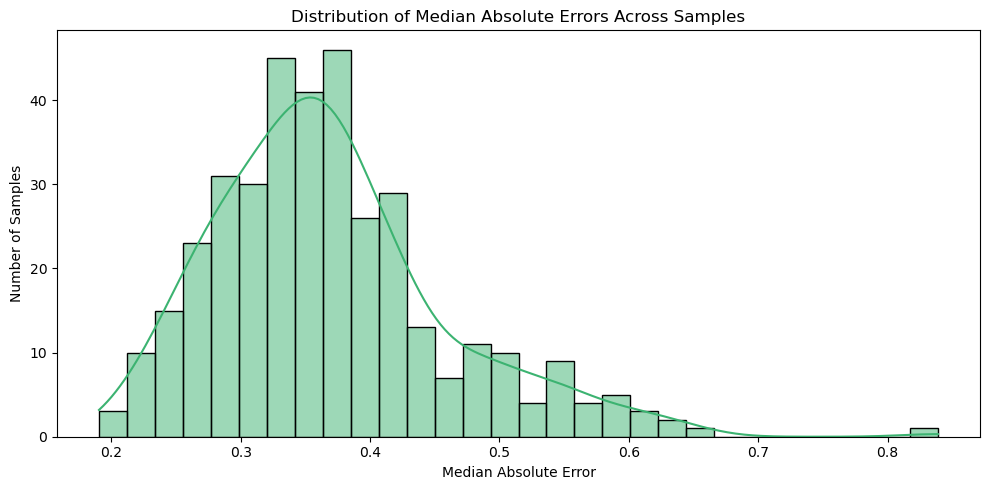

In [ ]:
# Compute median absolute error across proteins for each sample
sample_medians = combined_df.groupby("LOO sample")["abs_error"].median().reset_index()
sample_medians.rename(columns={"abs_error": "median_abs_error"}, inplace=True)

# Plot
plt.figure(figsize=(10, 5))
sns.histplot(sample_medians["median_abs_error"], bins=30, kde=True, color="mediumseagreen")

plt.title("Distribution of Median Absolute Errors Across Samples")
plt.xlabel("Median Absolute Error")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


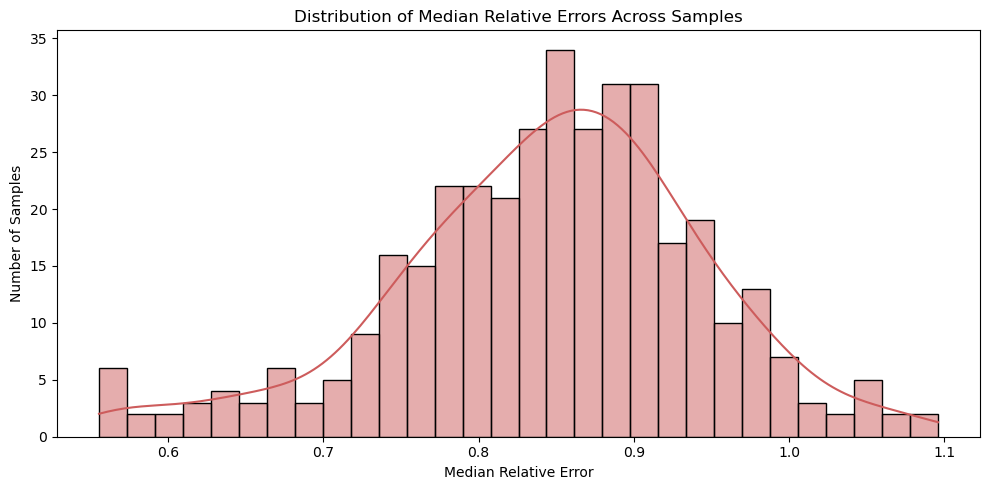

In [ ]:
# Compute median relative error across proteins for each sample
sample_medians_rel = combined_df.groupby("LOO sample")["rel_error"].median().reset_index()
sample_medians_rel.rename(columns={"rel_error": "median_rel_error"}, inplace=True)

# Plot
plt.figure(figsize=(10, 5))
sns.histplot(sample_medians_rel["median_rel_error"], bins=30, kde=True, color="indianred")

plt.title("Distribution of Median Relative Errors Across Samples")
plt.xlabel("Median Relative Error")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


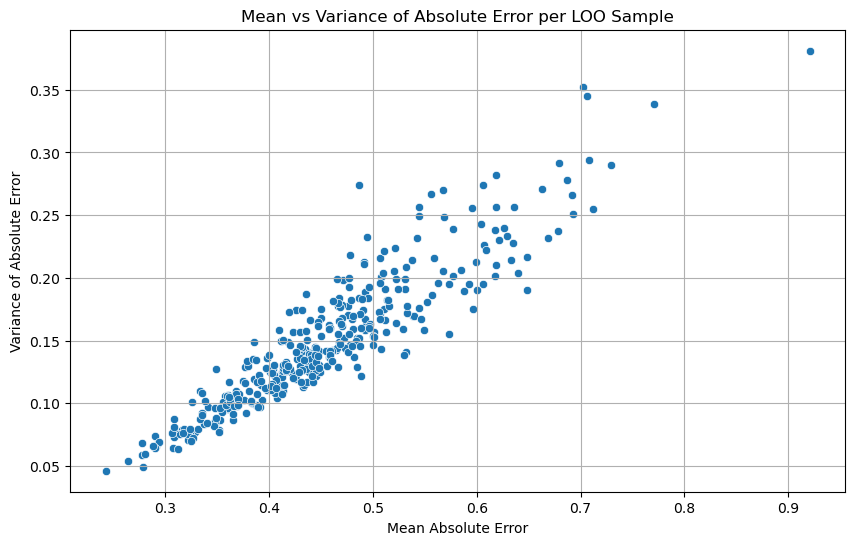

In [ ]:
sample_stats = combined_df.groupby('LOO sample')['abs_error'].agg(['mean', 'var']).reset_index()

# Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample_stats, x='mean', y='var')
plt.title("Mean vs Variance of Absolute Error per LOO Sample")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Variance of Absolute Error")
plt.grid(True)
plt.show()


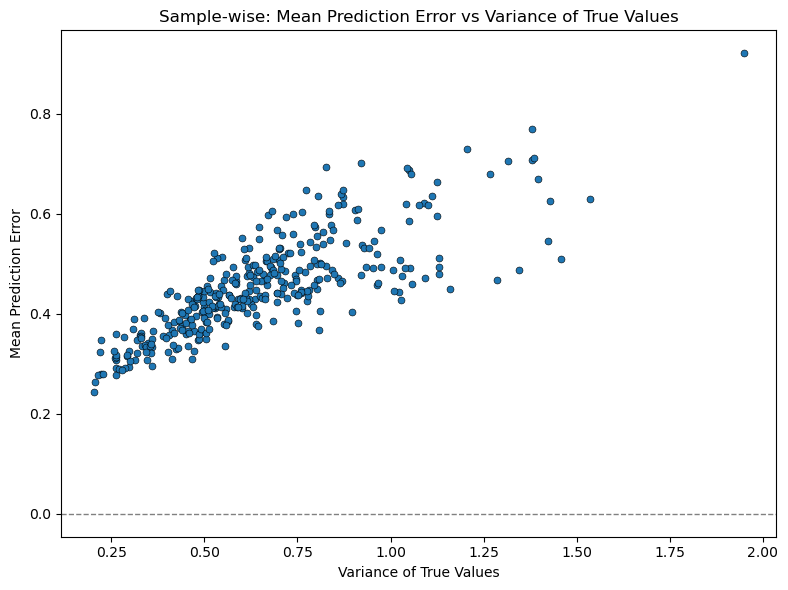

In [18]:
# Aggregate per LOO sample
sample_stats = (
    combined_df
    .groupby('LOO sample')
    .agg(
        mean_error = ('abs_error', 'mean'),
        var_true    = ('true', 'var'),
    )
    .reset_index()
)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=sample_stats,
    x='var_true',
    y='mean_error',
    s=25,
    edgecolor='k'
)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Sample‑wise: Mean Prediction Error vs Variance of True Values')
plt.xlabel('Variance of True Values')
plt.ylabel('Mean Prediction Error')
plt.tight_layout()
plt.show()